# Plotting predictions

The `plot_components` module builds a figure from a list of panels stacked over
a shared genomic interval. Pass the panels and the interval to
`plot_components.plot`, which returns a `matplotlib` figure you can save with
`fig.savefig`.

Panels fall into two groups:

*   **Annotations** mark genes, variants, and other intervals:
    `TranscriptAnnotation`, `VariantAnnotation`, and `IntervalAnnotation`.
*   **Data panels** show predictions: `Tracks` for coverage, `GeneExpression`
    for gene-level single-cell expression, `Sashimi` for splice junctions, and
    `ContactMaps` for 3D contacts. Overlaid versions compare REF and ALT
    alleles on the same axes.

Track labels are built from track metadata with `ylabel_template`, for example
`'{biosample_name} ({strand})'`.

For variant overlays and splice junction arcs in context, see
[Predicting a variant](https://www.alphagenomedocs.com/colabs/v2/predict_variant.html)
and
[Analyzing a splicing variant](https://www.alphagenomedocs.com/colabs/v2/splicing_variant.html).
The [Visualization API reference](https://www.alphagenomedocs.com/api/visualization.html)
lists every component and parameter.

## Set up

In [1]:
# @title Install AlphaGenome

# @markdown Run this cell to install AlphaGenome.
from IPython.display import clear_output
! pip install alphagenome
clear_output()

Store your API key in Colab Secrets for persistent access across sessions (see [Installation](https://www.alphagenomedocs.com/installation.html#add-api-key-to-secrets)).

In [2]:
from alphagenome import colab_utils
from alphagenome.data import gene_annotation, gene_expression_data, genome, track_data, transcript
from alphagenome.models.v2 import dna_client
from alphagenome.visualization import plot_components
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

### Load model and auxiliary objects

In [3]:
dna_model = dna_client.create(colab_utils.get_api_key())

In [4]:
# Load observed metadata objects for human.
output_metadata = dna_model.observed_metadata(
    organism=dna_client.Organism.HOMO_SAPIENS
)

In [5]:
# Load gene annotations (from GENCODE).
gtf = pd.read_feather(
    'https://storage.googleapis.com/alphagenome/reference/gencode/'
    'hg38/gencode.v46.annotation.gtf.gz.feather'
)

# Filter to protein-coding genes and highly supported transcripts.
gtf_transcript = gene_annotation.filter_transcript_support_level(
    gene_annotation.filter_protein_coding(gtf), ['1']
)

# Extractor for identifying transcripts in a region.
transcript_extractor = transcript.TranscriptExtractor(gtf_transcript)

# Also define an extractor that fetches only the longest transcript per gene.
gtf_longest_transcript = gene_annotation.filter_to_longest_transcript(
    gtf_transcript
)
longest_transcript_extractor = transcript.TranscriptExtractor(
    gtf_longest_transcript
)

## RNA-seq and CAGE coverage

`RNA_SEQ` and `CAGE` are coverage tracks that measure gene expression signal.
We predict `RNA_SEQ` and `CAGE` in sigmoid colon tissue for a genomic interval
containing *APOL4*. Positions of the longest transcript per gene in this
interval are shown at the top:

In [6]:
# Define interval to make predictions for (used throughout this tutorial).
# Note that the interval width must be one of the supported sequence lengths.
interval = genome.Interval('chr22', 36_150_498, 36_252_898).resize(
    dna_client.SEQUENCE_LENGTH_1MB
)

# Define the tissue/cell-type to predict expression for.
condition = 'UBERON:0001159'  # Colon - Sigmoid

# Make predictions.
output = dna_model.predict_interval(
    interval=interval,
    requested_outputs={
        dna_client.OutputType.RNA_SEQ,
        dna_client.OutputType.CAGE,
    },
    condition=condition,
)
# Extract the longest transcripts per gene for this interval.
longest_transcripts = longest_transcript_extractor.extract(interval)

Pass a list of panels to `plot_components.plot`:

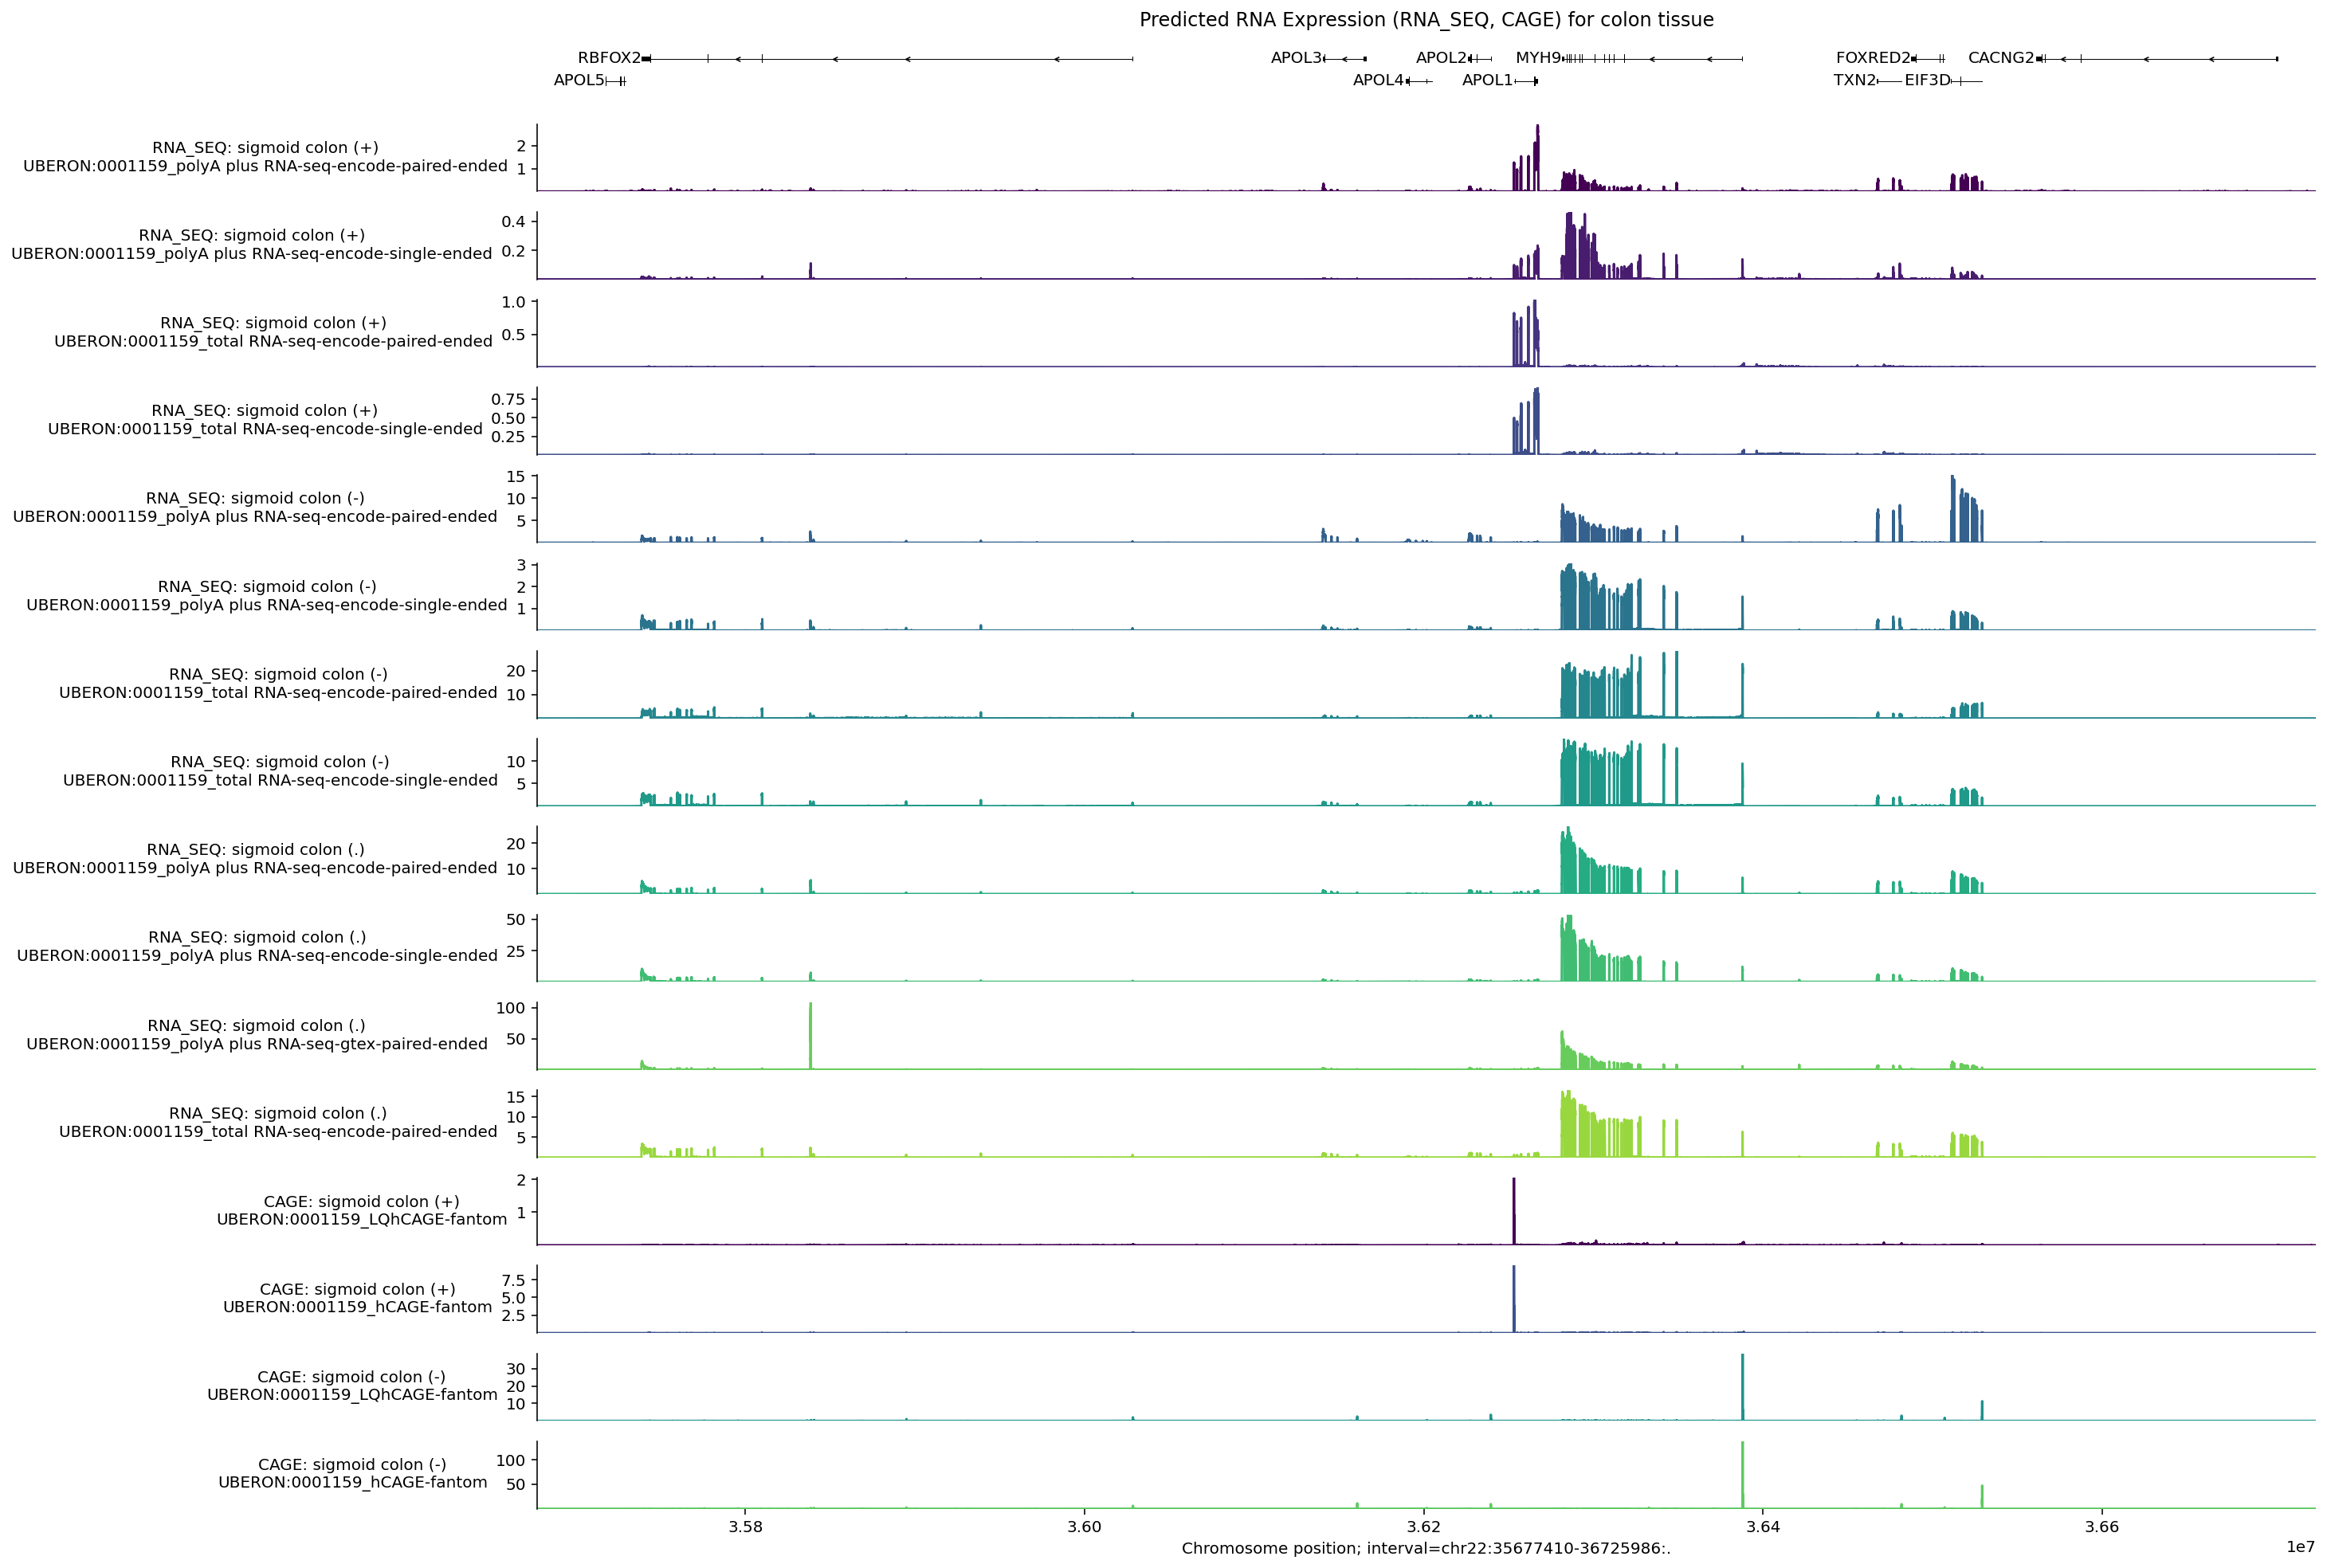

In [7]:
# Build plot.
plot = plot_components.plot(
    [
        plot_components.TranscriptAnnotation(longest_transcripts),
        plot_components.Tracks(
            tdata=output.rna_seq,
            ylabel_template='RNA_SEQ: {biosample_name} ({strand})\n{name}',
        ),
        plot_components.Tracks(
            tdata=output.cage,
            ylabel_template='CAGE: {biosample_name} ({strand})\n{name}',
        ),
    ],
    interval=interval,
    title='Predicted RNA Expression (RNA_SEQ, CAGE) for colon tissue',
)

Note that the positive and negative stranded tracks have clearly different
signals. Let's check which genes are transcribed from the positive strand:

In [8]:
[t.info['gene_name'] for t in longest_transcripts if t.strand == '+']

['APOL5', 'APOL1']

For both positive-strand `RNA_SEQ` tracks, RNA-seq coverage is highest across
*APOL1*. Similarly for `CAGE`, positive-strand peaks fall near the start of
*APOL1*, whereas *APOL5* shows no peaks because it is not expressed in colon
tissue [(GTEx)](https://www.gtexportal.org/home/gene/APOL5#geneExpression).

### Zoom in and customize track labels

The model predicts across the full 1 Mb input window, while `interval=` in
`plot_components.plot` controls the plotted window. Including
`{imputation_mode}` in `ylabel_template` indicates whether each track was
directly measured (`observed`) or imputed in the target condition:

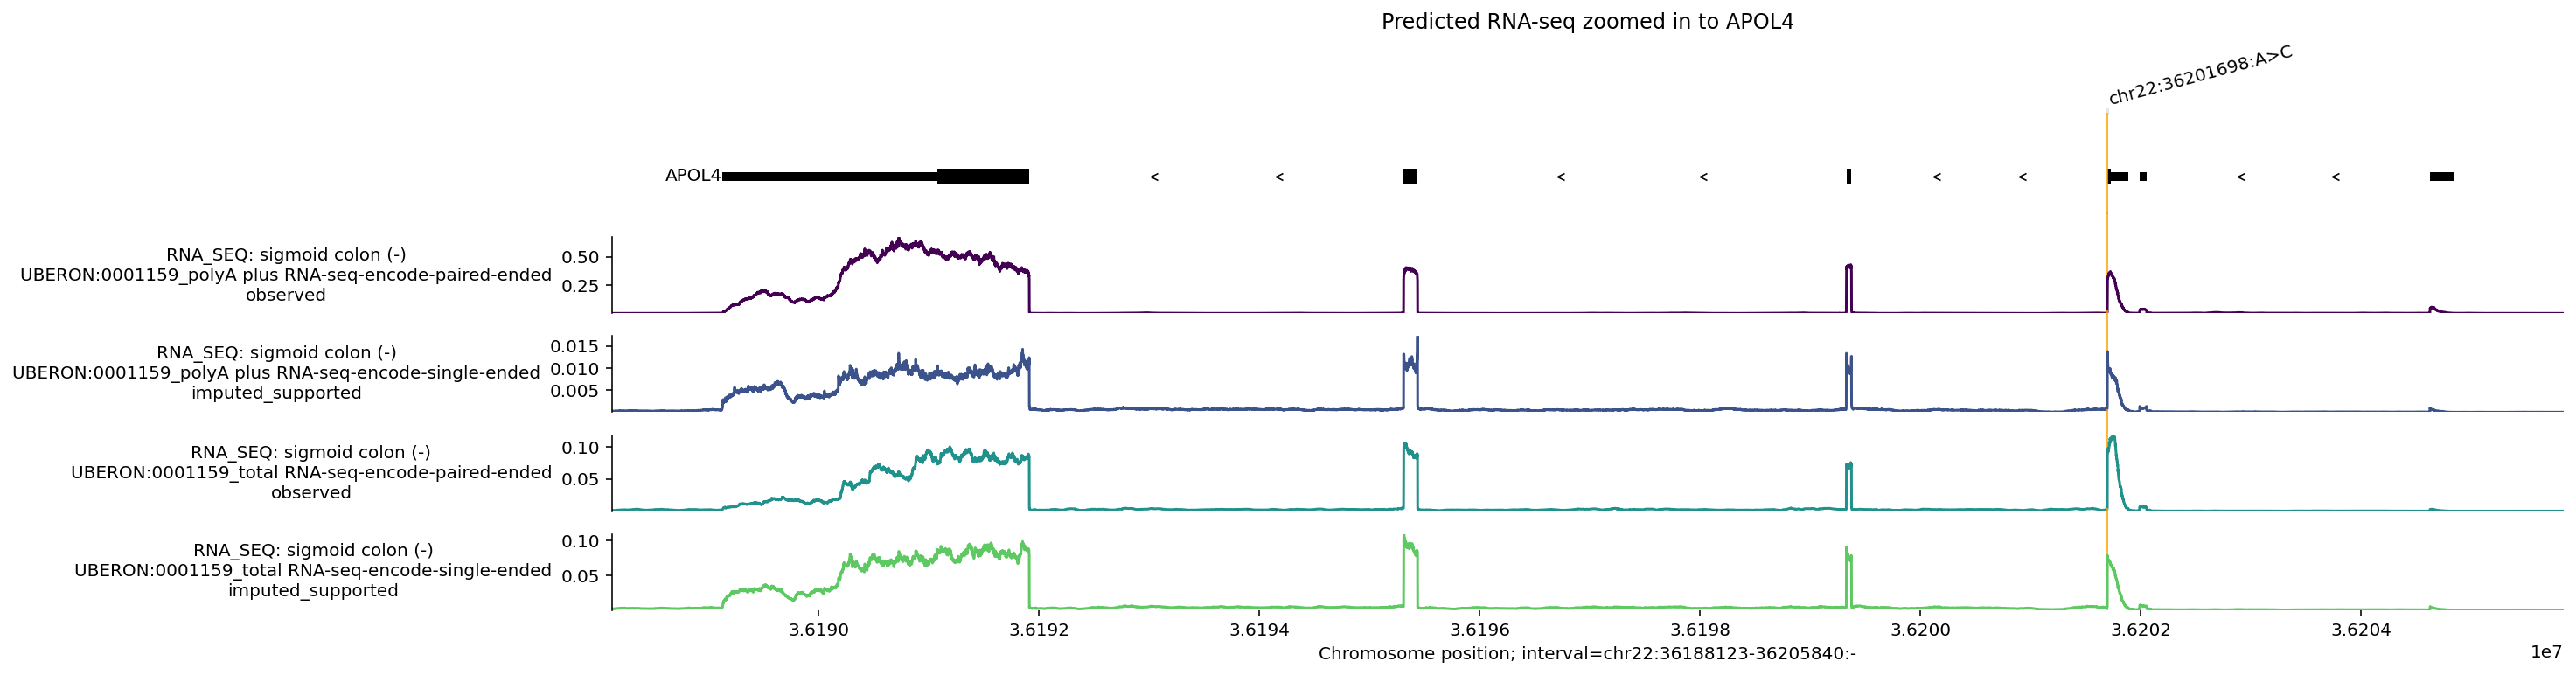

In [9]:
apol4_interval = gene_annotation.get_gene_interval(gtf, gene_symbol='APOL4')
apol4_interval = apol4_interval.resize(apol4_interval.width + 2000)
transcripts = transcript_extractor.extract(interval)

variant = genome.Variant.from_str('chr22_36201698_A_C', genome.VariantFormat.GTEX)

fig = plot_components.plot(
    [
        plot_components.TranscriptAnnotation(longest_transcripts),
        plot_components.Tracks(
            tdata=output.rna_seq.filter_to_negative_strand(),
            ylabel_template=(
                'RNA_SEQ: {biosample_name} ({strand})\n{name}\n{imputation_mode}'
            ),
        ),
    ],
    interval=apol4_interval,
    annotations=[plot_components.VariantAnnotation([variant])],
    title='Predicted RNA-seq zoomed in to APOL4',
)
plt.show()

### Plot custom annotation (e.g., polyadenylation sites)

In [10]:
# Run predictions with an additional ontology to highlight differences across
# tissues.
conditions = [
    'UBERON:0001159',  # Colon - Sigmoid.
    'UBERON:0002048',  # lung.
]

# Make predictions.
outputs = [
    dna_model.predict_interval(
        interval=interval,
        requested_outputs={
            dna_client.OutputType.RNA_SEQ,
        },
        condition=condition,
    )
    for condition in conditions
]

There are 3 annotated polyadenylation (pA) sites overlapping *APOL4* transcripts
from [PolyADBv3](https://exon.apps.wistar.org/polya_db/v3/misc/download.php)
[(Wang *et al.* 2018)](https://pubmed.ncbi.nlm.nih.gov/29069441/). We define
these positions as 1 bp intervals in hg38 coordinates:

In [11]:
# Define pA sites in hg38 coordinates.
apol4_pAs = [
    genome.Interval('chr22', 36_189_128, 36_189_129, '-'),
    genome.Interval('chr22', 36_190_089, 36_190_090, '-'),
    genome.Interval('chr22', 36_190_144, 36_190_145, '-'),
]

# Define plotting interval as first/last pA plus some offset distance.

offset = 200
pA_interval = genome.Interval(
    'chr22', 36_189_128 - offset, 36_190_145 + offset, '-'
)

# Define intervals annotation.
pA_labels = ['pA_3', 'pA_2', 'pA_1']

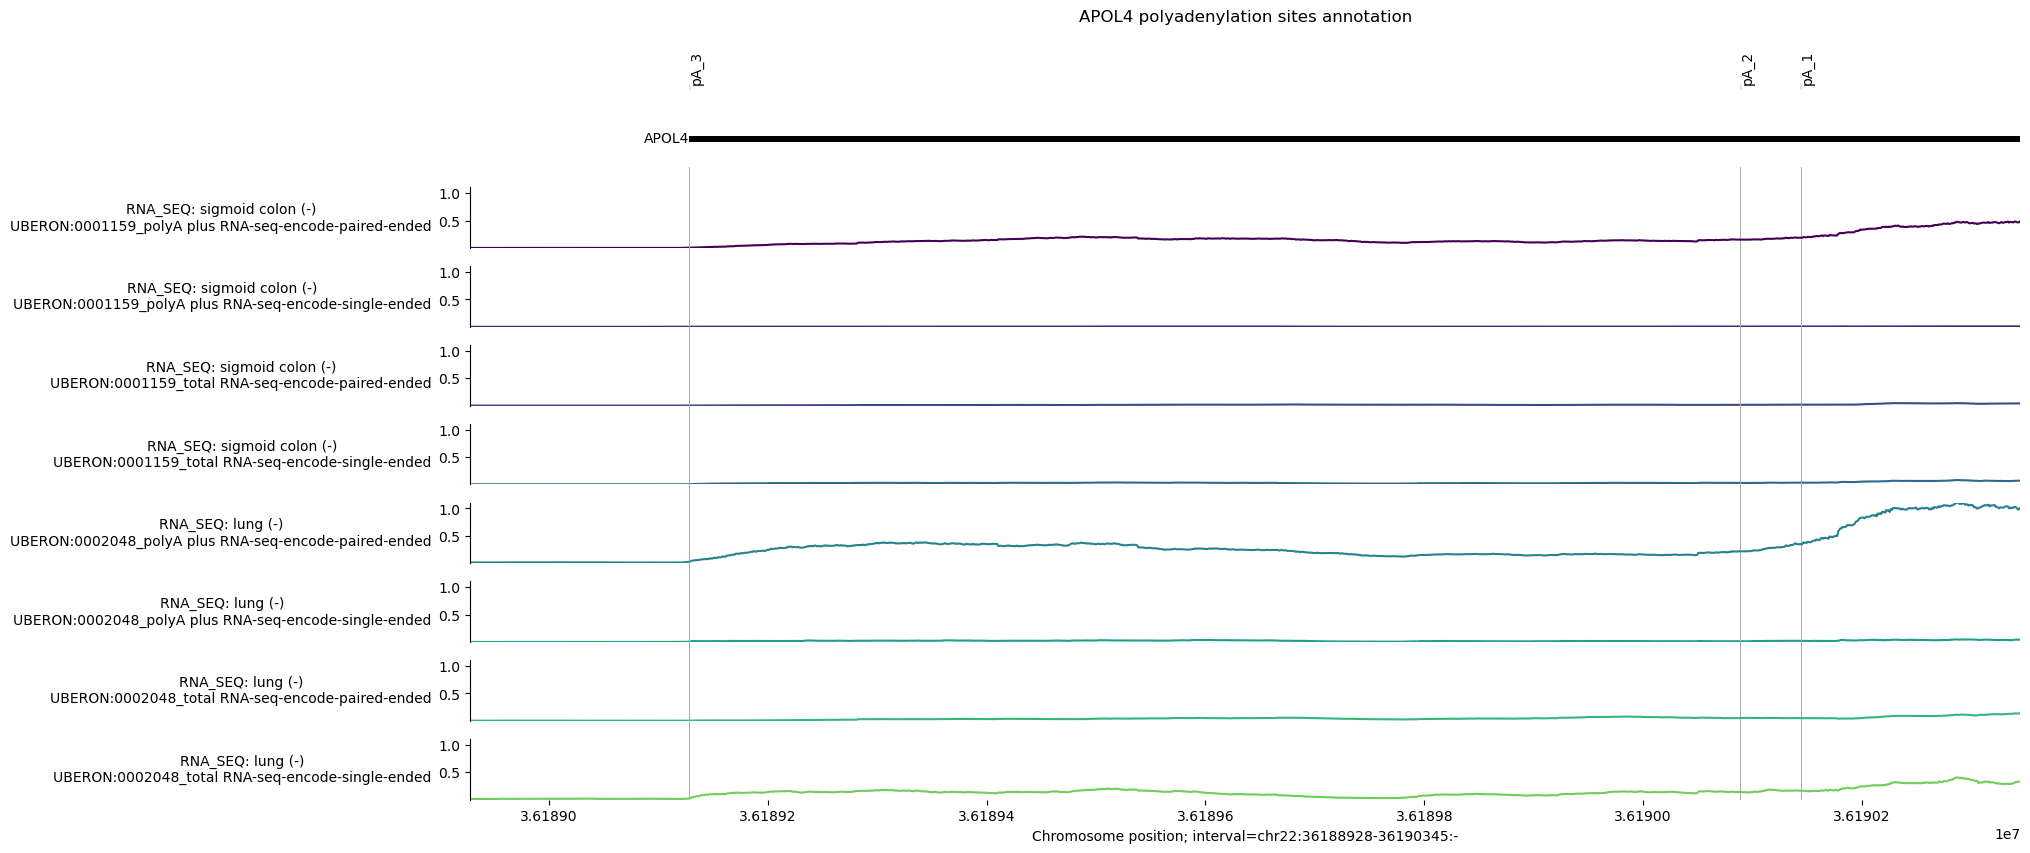

In [11]:
# Build plot.
# NOTE: Depending on annotation distance and interval zoom, some annotations may
# appear as overlapping.

plot = plot_components.plot(
    [
        plot_components.TranscriptAnnotation(longest_transcripts),
        # RNA-seq tracks.
        plot_components.Tracks(
            tdata=track_data.concat([
                output.rna_seq.filter_to_negative_strand() for output in outputs
            ]),
            ylabel_template='RNA_SEQ: {biosample_name} ({strand})\n{name}',
            shared_y_scale=True,
        ),
    ],
    annotations=[
        plot_components.IntervalAnnotation(
            apol4_pAs, alpha=1, labels=pA_labels, label_angle=90
        )
    ],
    interval=pA_interval,
    title='APOL4 polyadenylation sites annotation',
)

## Single-cell gene expression

For single-cell data, AlphaGenome 2 outputs a predicted expression value per gene
rather than a base-resolution coverage track.

To show gene-level values alongside coverage tracks, `GeneExpression` draws each
gene's predicted value as a horizontal segment over the gene body labeled in
counts per million (CPM). Here we compare placental epithelial cells, which
express *APOL4*, with placental T cells:

In [13]:
conditions = [
    'UBERON:0001987_CL:0000066',  # Placenta Epithelial Cell
    'UBERON:0001987_CL:0000084',  # Placenta T-cell
]

In [14]:
output = [
    dna_model.predict_interval(
        interval=interval,
        requested_outputs={
            dna_client.OutputType.SC_GENE_EXPRESSION,
        },
        condition=condition,
    )
    for condition in conditions
]

For `SC_GENE_EXPRESSION`, predictions are returned as `GeneExpressionData` objects
containing a gene-by-track `values` matrix alongside `gene_metadata` and
`track_metadata` tables. Convenience methods (`filter_to_protein_coding()`,
`filter_to_observed()`, `filter_to_negative_strand()`) or boolean masks filter
to genes and tracks of interest.

As with `track_data.concat` for `TrackData`, use `gene_expression_data.concat`
to combine predictions from multiple conditions:

In [15]:
# Concatenate predictions for the two queried ontologies
gex_pred = gene_expression_data.concat(
    [out.sc_gene_expression for out in output]
)

# Select only protein-coding genes and observed, negative strand tracks.
gex_pred = (
    gex_pred.filter_to_protein_coding()
    .filter_to_observed()
    .filter_to_negative_strand()
)

We can now use the `GeneExpression` component to plot the predicted gene
expression values.

```{tip}
To hide printed CPM labels on each gene bar, pass `show_value=False`. Setting
`log_scale=True` displays expression on a log1p scale so highly expressed neighbor
genes do not compress moderate-expression genes near zero.
```

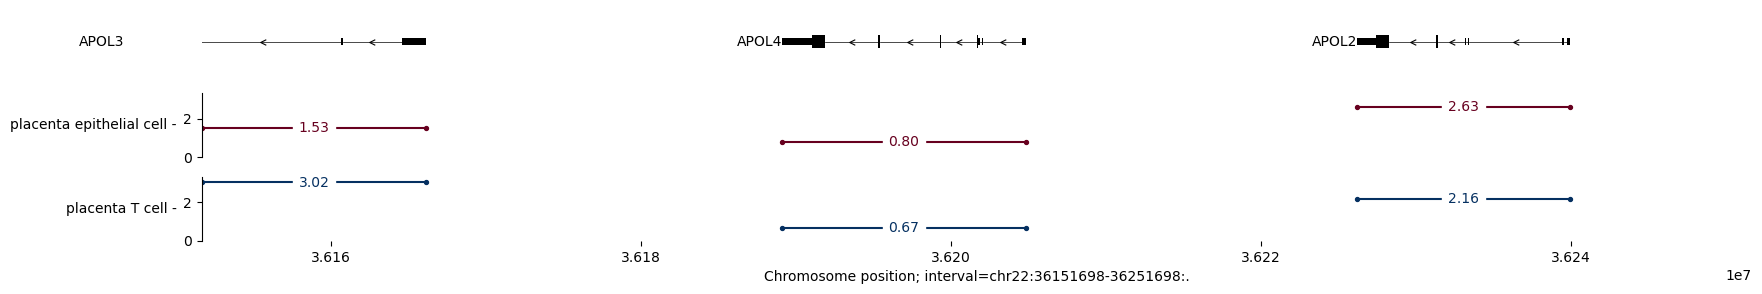

In [15]:
plot_components.plot(
    [
        plot_components.TranscriptAnnotation(longest_transcripts),
        plot_components.GeneExpression(
            gdata=gex_pred,
            ylabel_template='{biosample_name} {strand}',
            cmap='RdBu',
            log_scale=True,
            shared_y_scale=True,
        ),
    ],
    interval=interval.resize(100_000),  # We zoom in on APOL4
)
plt.show()

As expected, we observe higher expression of *APOL4* in placental epithelial
cells than in T cells, and the opposite pattern for *APOL3*.

## Chromatin accessibility

Chromatin accessibility is captured by the `DNASE`, `ATAC`, and `SC_ATAC` output
types. We show `ATAC` and `DNASE` here (`SC_ATAC` can be requested the same
way), plotting predictions across intestinal tract reference conditions for the
interval around *APOL4*:

In [17]:
# List of IDs corresponding to various intestinal tissues.
conditions = [
    'UBERON:0000317',
    'UBERON:0001155',
    'UBERON:0001157',
    'UBERON:0001159',
    'UBERON:0004992',
    'UBERON:0008971',
]

In [18]:
# Make predictions.
outputs = [
    dna_model.predict_interval(
        interval,
        requested_outputs={
            dna_client.OutputType.DNASE,
            dna_client.OutputType.ATAC,
        },
        condition=condition,
    )
    for condition in conditions
]

Use `plot_components.IntervalAnnotation` to mark two putative promoters from the
Ensembl Regulatory Build and check whether they overlap predicted accessible
regions:

In [19]:
# Two putative promoter intervals from Ensembl.
promoter_intervals = [
    genome.Interval(
        'chr22', 36_201_799, 36_202_681, name='Ensembl_promoter:ENSR00001367790'
    ),
    genome.Interval(
        'chr22', 36_204_705, 36_205_330, name='Ensembl_promoter:ENSR00001367792'
    ),
]

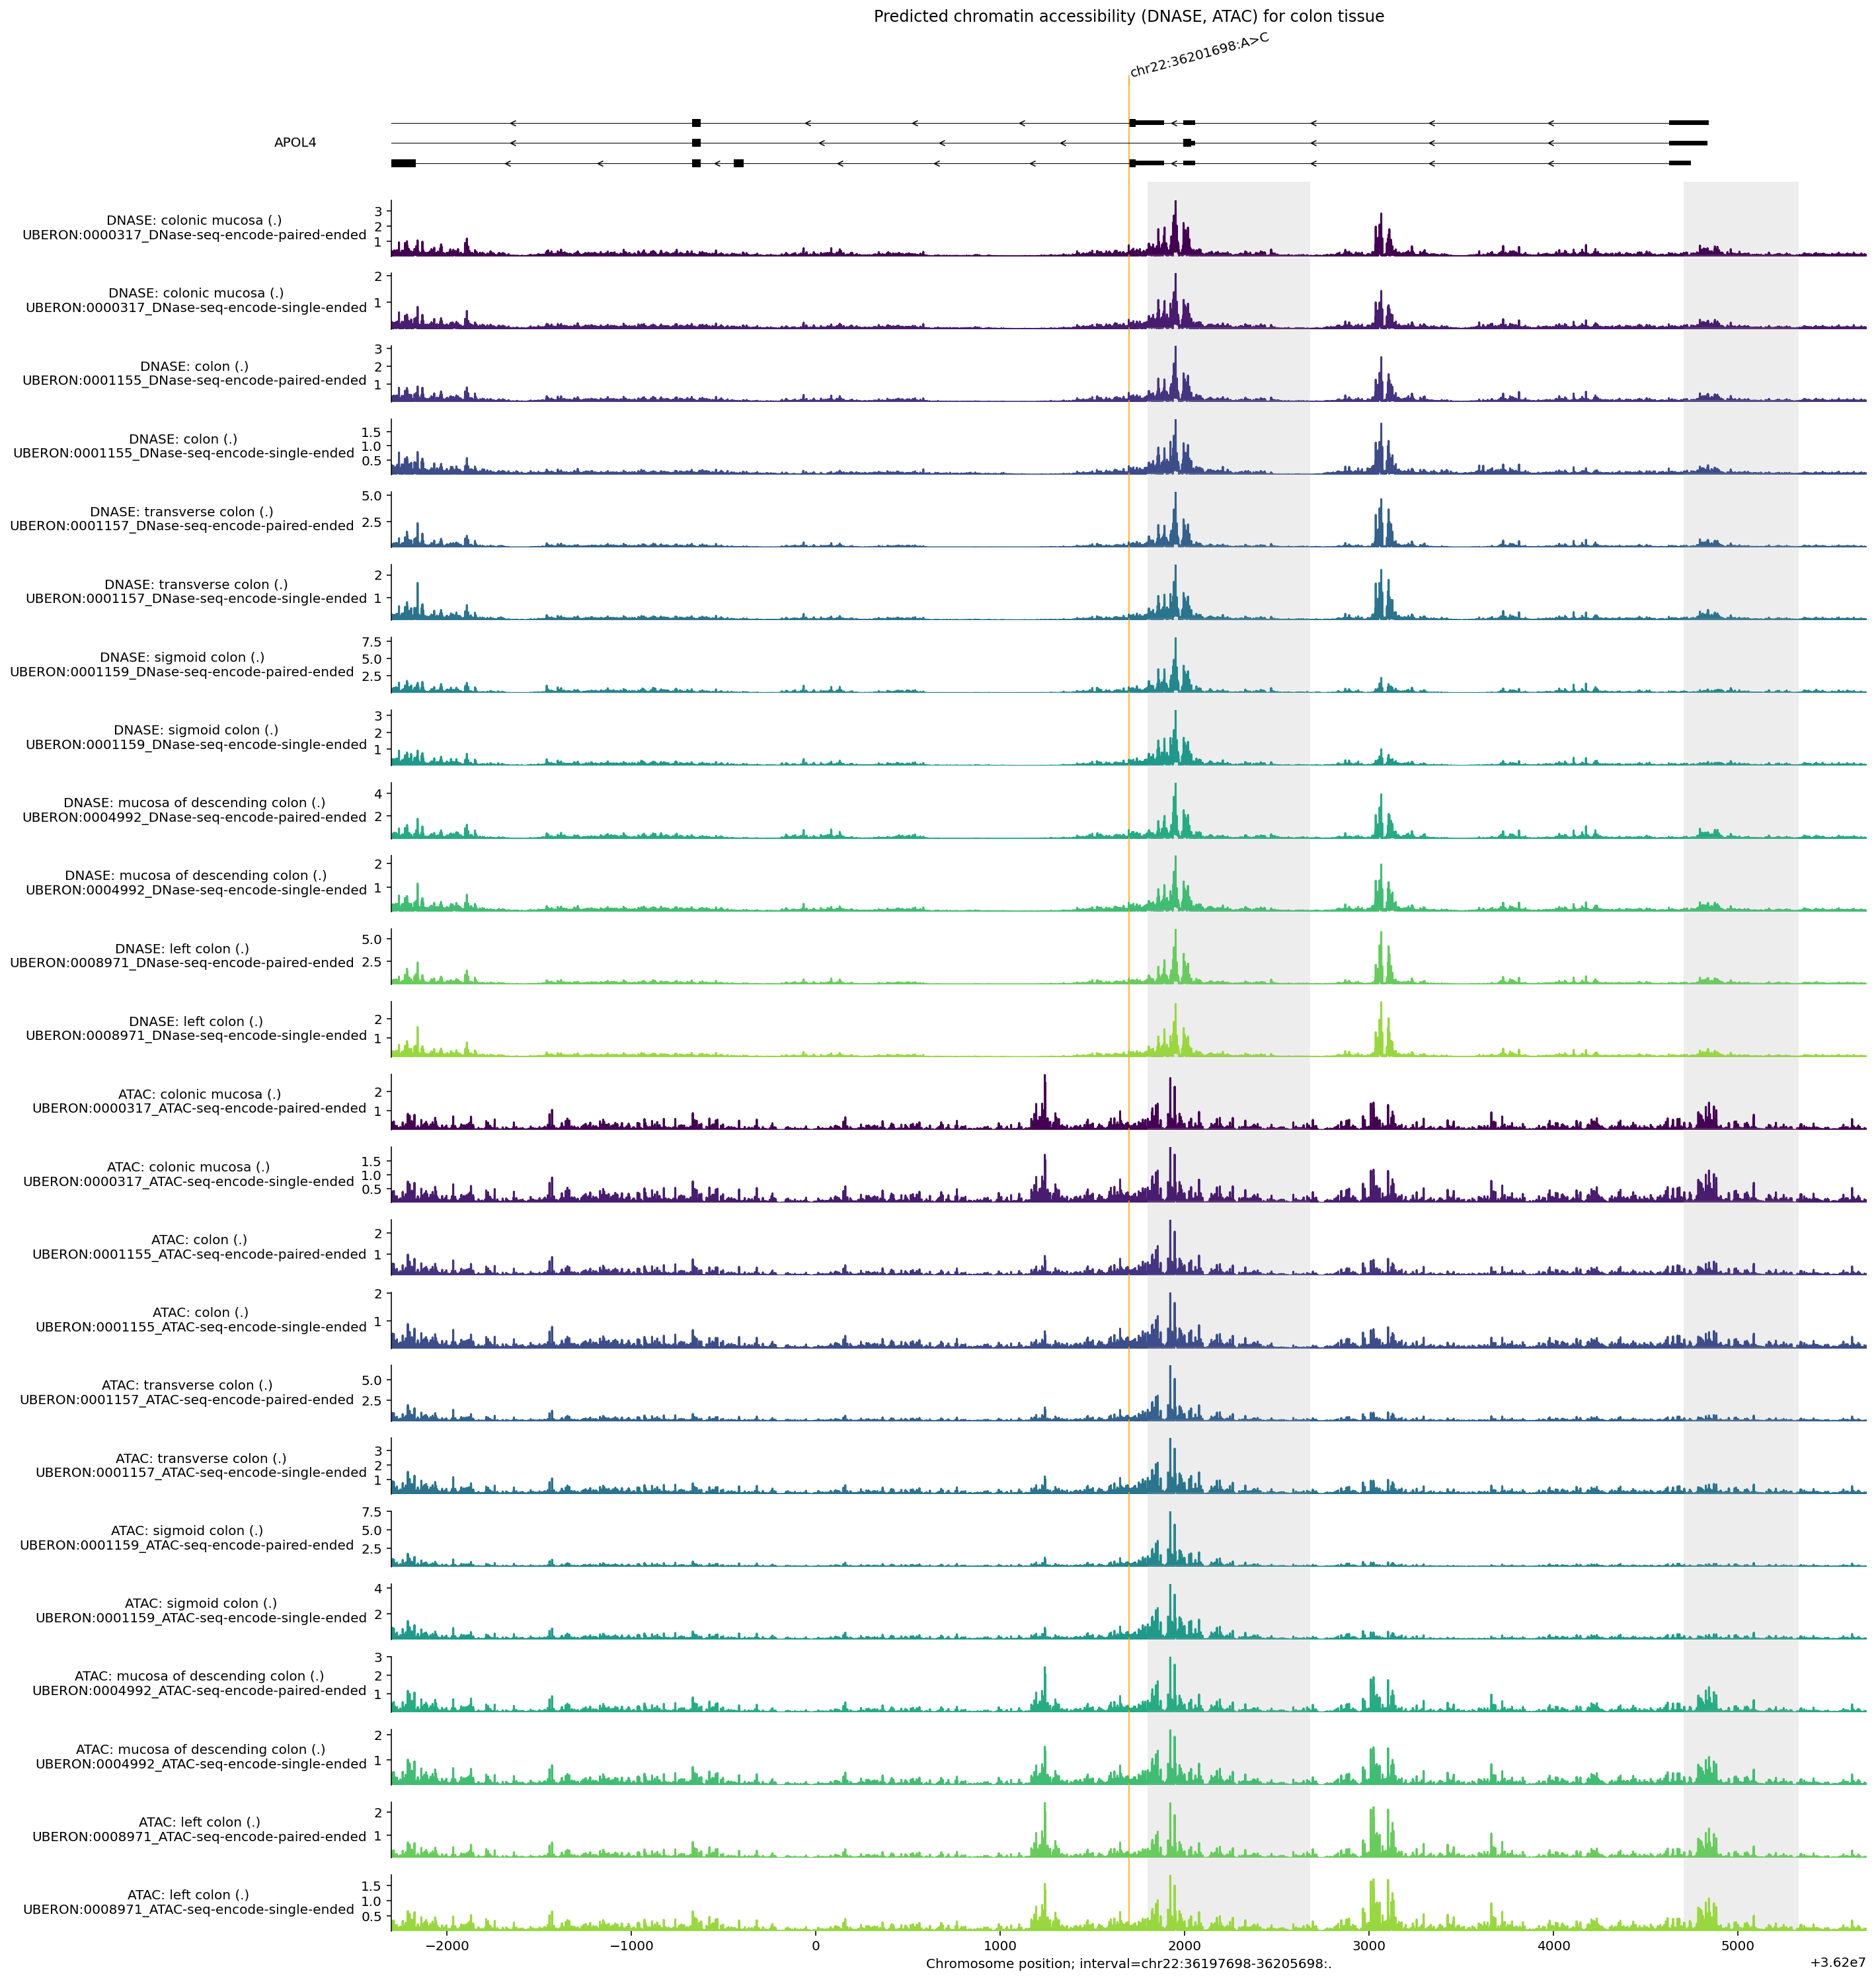

In [20]:
# Build plot.
plot = plot_components.plot(
    [
        plot_components.TranscriptAnnotation(longest_transcripts),
        plot_components.Tracks(
            tdata=track_data.concat([output.dnase for output in outputs]),
            ylabel_template='DNASE: {biosample_name} ({strand})\n{name}',
        ),
        plot_components.Tracks(
            tdata=track_data.concat([output.atac for output in outputs]),
            ylabel_template='ATAC: {biosample_name} ({strand})\n{name}',
        ),
    ],
    # Plot an 8kb window around the variant.
    interval=variant.reference_interval.resize(8000),
    annotations=[
        plot_components.VariantAnnotation([variant]),
        plot_components.IntervalAnnotation(promoter_intervals),
    ],
    title='Predicted chromatin accessibility (DNASE, ATAC) for colon tissue',
)

Observations from this plot:
*   Elevated `DNASE` and `ATAC` signals overlap both putative promoter regions
    highlighted in grey, and additional accessibility peaks mark candidate
    distal regulatory elements.
*   `DNASE` and `ATAC` signals are similar but not identical, reflecting differences
    in assay protocol.
*   Accessibility is low directly at the variant position (orange line).

## Histone ChIP-seq

Histone modification marks are captured by the `CHIP_HISTONE` output. Here we
visualize predictions across the same interval for colon tissues.

Two properties apply to `CHIP_HISTONE` (and `CHIP_TF`) predictions in
AlphaGenome 2:

*   Predictions are returned at 128 bp resolution, and `plot_components` aligns
    plotted intervals to bin boundaries automatically.
*   Every supported condition returns all 43 histone ChIP channels (covering 32 marks split by sequencing endedness). Use `dna_model.observed_metadata(...)` or `metadata['imputation_mode']` to inspect which histone marks were directly measured (`observed`) in each tissue:

In [21]:
output_metadata.chip_histone[
    output_metadata.chip_histone['biosample_name'].str.contains('colon')
]

,name,strand,biosample_curie,imputation_mode,biosample_type,biosample_name,Assay title,data_source,histone_mark,genetically_modified,endedness,data_pipeline
191,UBERON:0000317_Histone ChIP-seq-encode-H3K27ac...,.,UBERON:0000317,observed,tissue,colonic mucosa,Histone ChIP-seq,encode,H3K27ac,False,single,encode
192,UBERON:0000317_Histone ChIP-seq-encode-H3K27me...,.,UBERON:0000317,observed,tissue,colonic mucosa,Histone ChIP-seq,encode,H3K27me3,False,single,encode
193,UBERON:0000317_Histone ChIP-seq-encode-H3K36me...,.,UBERON:0000317,observed,tissue,colonic mucosa,Histone ChIP-seq,encode,H3K36me3,False,single,encode
194,UBERON:0000317_Histone ChIP-seq-encode-H3K4me1...,.,UBERON:0000317,observed,tissue,colonic mucosa,Histone ChIP-seq,encode,H3K4me1,False,single,encode
195,UBERON:0000317_Histone ChIP-seq-encode-H3K4me3...,.,UBERON:0000317,observed,tissue,colonic mucosa,Histone ChIP-seq,encode,H3K4me3,False,single,encode
196,UBERON:0000317_Histone ChIP-seq-encode-H3K9ac-...,.,UBERON:0000317,observed,tissue,colonic mucosa,Histone ChIP-seq,encode,H3K9ac,False,single,encode
218,UBERON:0001157_Histone ChIP-seq-encode-H3K27ac...,.,UBERON:0001157,observed,tissue,transverse colon,Histone ChIP-seq,encode,H3K27ac,False,single,encode
219,UBERON:0001157_Histone ChIP-seq-encode-H3K27me...,.,UBERON:0001157,observed,tissue,transverse colon,Histone ChIP-seq,encode,H3K27me3,False,single,encode
220,UBERON:0001157_Histone ChIP-seq-encode-H3K36me...,.,UBERON:0001157,observed,tissue,transverse colon,Histone ChIP-seq,encode,H3K36me3,False,single,encode
221,UBERON:0001157_Histone ChIP-seq-encode-H3K4me1...,.,UBERON:0001157,observed,tissue,transverse colon,Histone ChIP-seq,encode,H3K4me1,False,single,encode


In [22]:
# List of IDs corresponding to various colon tissues in `CHIP_HISTONE` output.
conditions = [
    'UBERON:0000317',
    'UBERON:0001155',
    'UBERON:0001157',
    'UBERON:0001159',
]

# Make predictions.
outputs = [
    dna_model.predict_interval(
        interval=interval,
        requested_outputs={dna_client.OutputType.CHIP_HISTONE},
        condition=condition,
    )
    for condition in conditions
]

We can extract the locations of transcription start sites as annotated by
GENCODE using `gene_annotation.extract_tss()`, and plot these using
`plot_components.IntervalAnnotation()`:

In [23]:
gtf_tss = gene_annotation.extract_tss(gtf_longest_transcript)

tss_as_intervals = [
    genome.Interval(
        chromosome=row.Chromosome,
        start=row.Start,
        end=row.End + 1000,  # Add extra 1Kb so the TSSs are visible.
        name=row.gene_name,
    )
    for _, row in gtf_tss.iterrows()
]

We can also reorder tracks so they are grouped by histone mark, and also specify
colors based on their histone mark:

In [24]:
concatenated_outputs = track_data.concat(
    [output.chip_histone for output in outputs]
)
reordered_chip_histone = concatenated_outputs.select_tracks_by_index(
    concatenated_outputs.metadata.sort_values('histone_mark').index
)

histone_to_color = {
    'H3K27AC': '#e41a1c',
    'H3K36ME3': '#ff7f00',
    'H3K4ME1': '#377eb8',
    'H3K4ME3': '#984ea3',
    'H3K9AC': '#4daf4a',
    'H3K27ME3': '#ffc0cb',
}
track_colors = (
    reordered_chip_histone.metadata['histone_mark']
    .map(lambda x: histone_to_color.get(x.upper(), '#000000'))
    .values
)

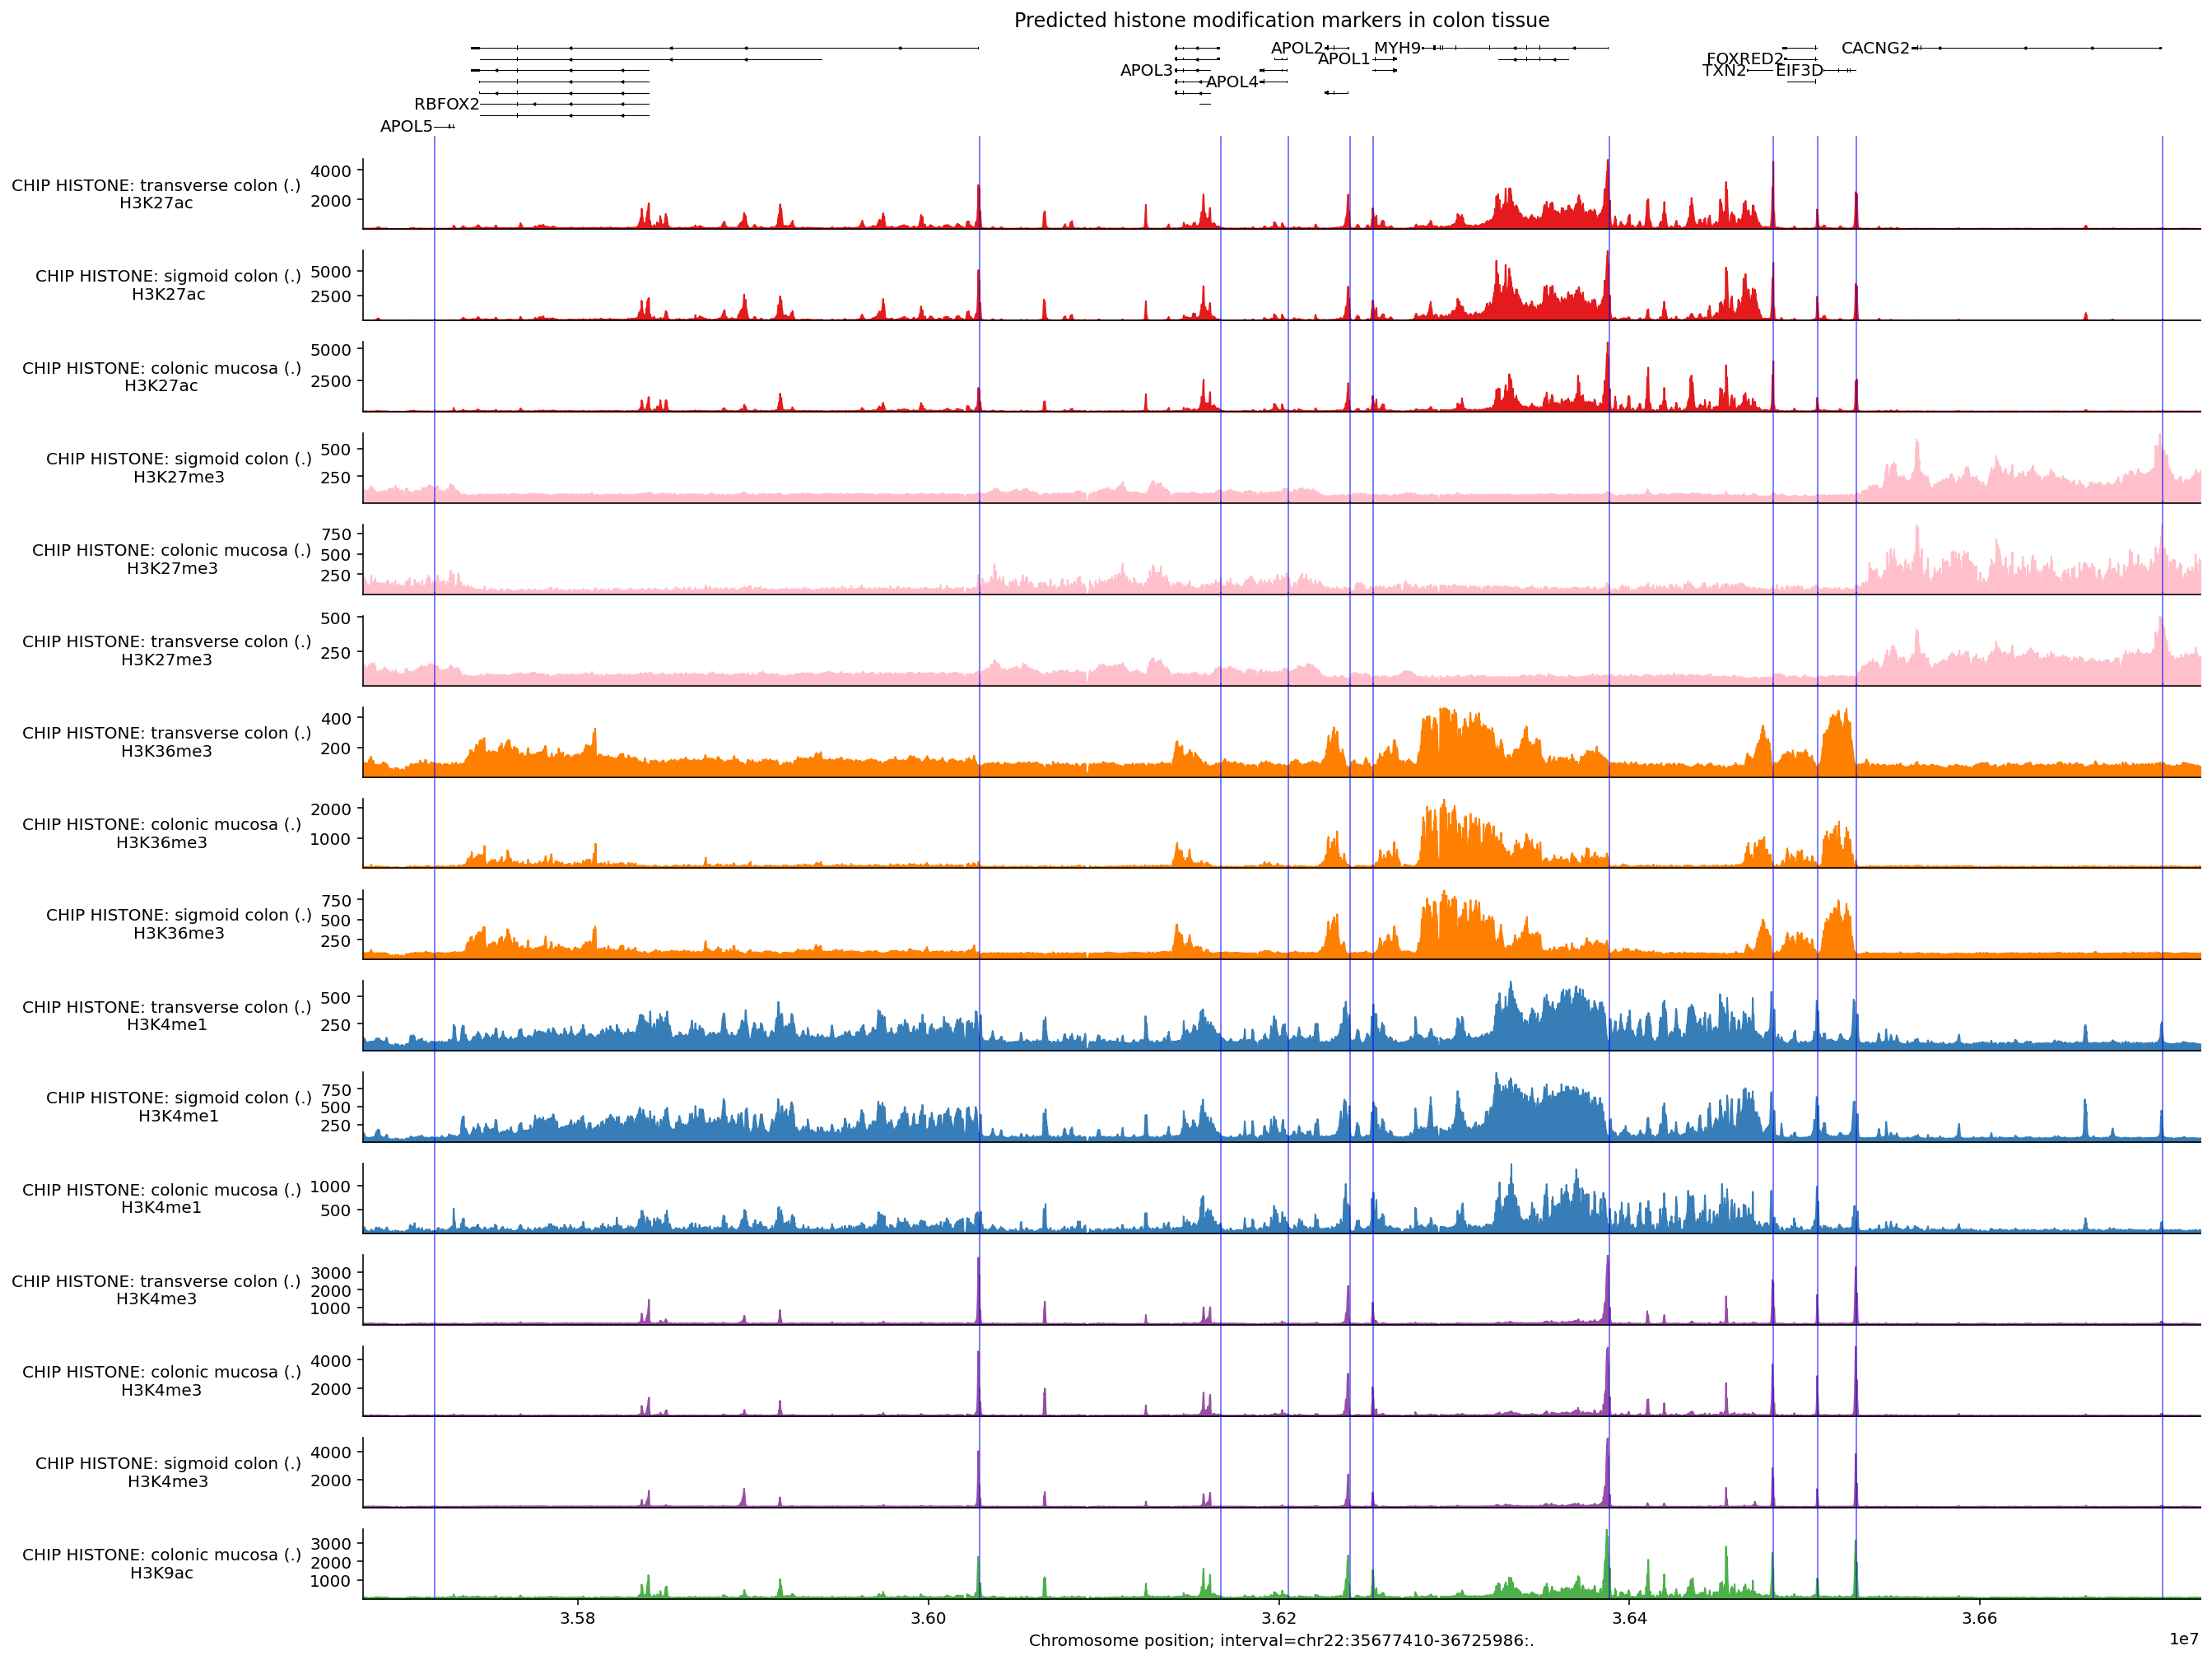

In [25]:
# Build plot.
observed_tracks_mask = (
    reordered_chip_histone.metadata['imputation_mode'] == 'observed'
).values
plot = plot_components.plot(
    [
        plot_components.TranscriptAnnotation(longest_transcripts),
        plot_components.Tracks(
            tdata=reordered_chip_histone.filter_tracks(observed_tracks_mask),
            ylabel_template=(
                'CHIP HISTONE: {biosample_name} ({strand})\n{histone_mark}'
            ),
            filled=True,
            track_colors=track_colors[observed_tracks_mask],
        ),
    ],
    interval=interval,
    annotations=[
        plot_components.IntervalAnnotation(
            tss_as_intervals, alpha=0.5, colors='blue'
        )
    ],
    despine_keep_bottom=True,
    title='Predicted histone modification markers in colon tissue',
)

We can see that many of the predicted histone modification peaks overlap with
transcription start sites, especially markers associated with promoters
(H3K4me3, H3K27ac, and H3K9ac). Other markers such as H3K36me3 and H3K4me1 are
more associated with gene bodies and enhancers, so these signals are less
pronounced around the TSSs.

## TF ChIP-seq

Transcription factor (TF) binding patterns are captured by the `CHIP_TF` output
at 128 bp resolution. Every supported condition returns all 911 TF ChIP channels (covering 778 targets split by sequencing endedness); `dna_model.observed_metadata(...)` identifies which factors were directly assayed in each biosample (for example, HepG2 and K562 have observed TF ChIP-seq coverage across hundreds of factors).

Here we also demonstrate selecting specific tracks from a `TrackData` object and
aggregating signal across tracks:

In [26]:
conditions = [
    'UBERON:0001159',  # Sigmoid colon.
    'UBERON:0001157',  # Transverse colon.
    'EFO:0002067',  # K562.
    'EFO:0001187',  # HepG2.
]

outputs = [
    dna_model.predict_interval(
        interval=interval,
        requested_outputs={dna_client.OutputType.CHIP_TF},
        condition=condition,
    )
    for condition in conditions
]

concatenated_chip_tf = track_data.concat([output.chip_tf for output in outputs])

Say we then only want to work with the K562 and HepG2 part of the output. We can
accomplish this by calling `filter_tracks`:

In [27]:
conditions = [
    'EFO:0002067',  # K562.
    'EFO:0001187',  # HepG2.
]

output_chip_tf = concatenated_chip_tf.filter_tracks(
    (concatenated_chip_tf.metadata['biosample_curie'].isin(conditions)).values
)
len(output_chip_tf.metadata)

1822

Across the predicted TF ChIP-seq tracks for these two cell lines, maximum
predicted values vary substantially across factors:

In [28]:
max_predictions = output_chip_tf.metadata[
    ['biosample_curie', 'biosample_name', 'transcription_factor']
].copy()

max_predictions.loc[:, 'max_prediction'] = output_chip_tf.values.max(axis=0)
max_predictions.sort_values('max_prediction', ascending=False).reset_index(
    drop=True
)

,biosample_curie,biosample_name,transcription_factor,max_prediction
0,EFO:0002067,K562,E2F6,43330.480469
1,EFO:0002067,K562,MAX,34710.921875
2,EFO:0002067,K562,REST,33534.230469
3,EFO:0002067,K562,PKNOX1,33243.894531
4,EFO:0001187,HepG2,REST,32402.304688
...,...,...,...,...
1817,EFO:0002067,K562,GPBP1L1,158.165741
1818,EFO:0002067,K562,BCLAF1,152.707596
1819,EFO:0001187,HepG2,NR0B1,152.435913
1820,EFO:0001187,HepG2,COPS2,151.663513


To keep the multi-track plot legible across 1 Mb, we select only tracks whose
maximum predicted peak amplitude exceeds `10_000`, which isolates the handful of
highest-signal factors in this window:

In [29]:
print(f'Number of tracks before filtering: {len(output_chip_tf.metadata)}')

output_filtered = output_chip_tf.filter_tracks(
    output_chip_tf.values.max(axis=0) > 10_000
)
print(f'Number of tracks after filtering: {len(output_filtered.metadata)}')

Number of tracks before filtering: 1822
Number of tracks after filtering: 23


This is a more manageable number of tracks to visualize. Let's build up the plot
as before:

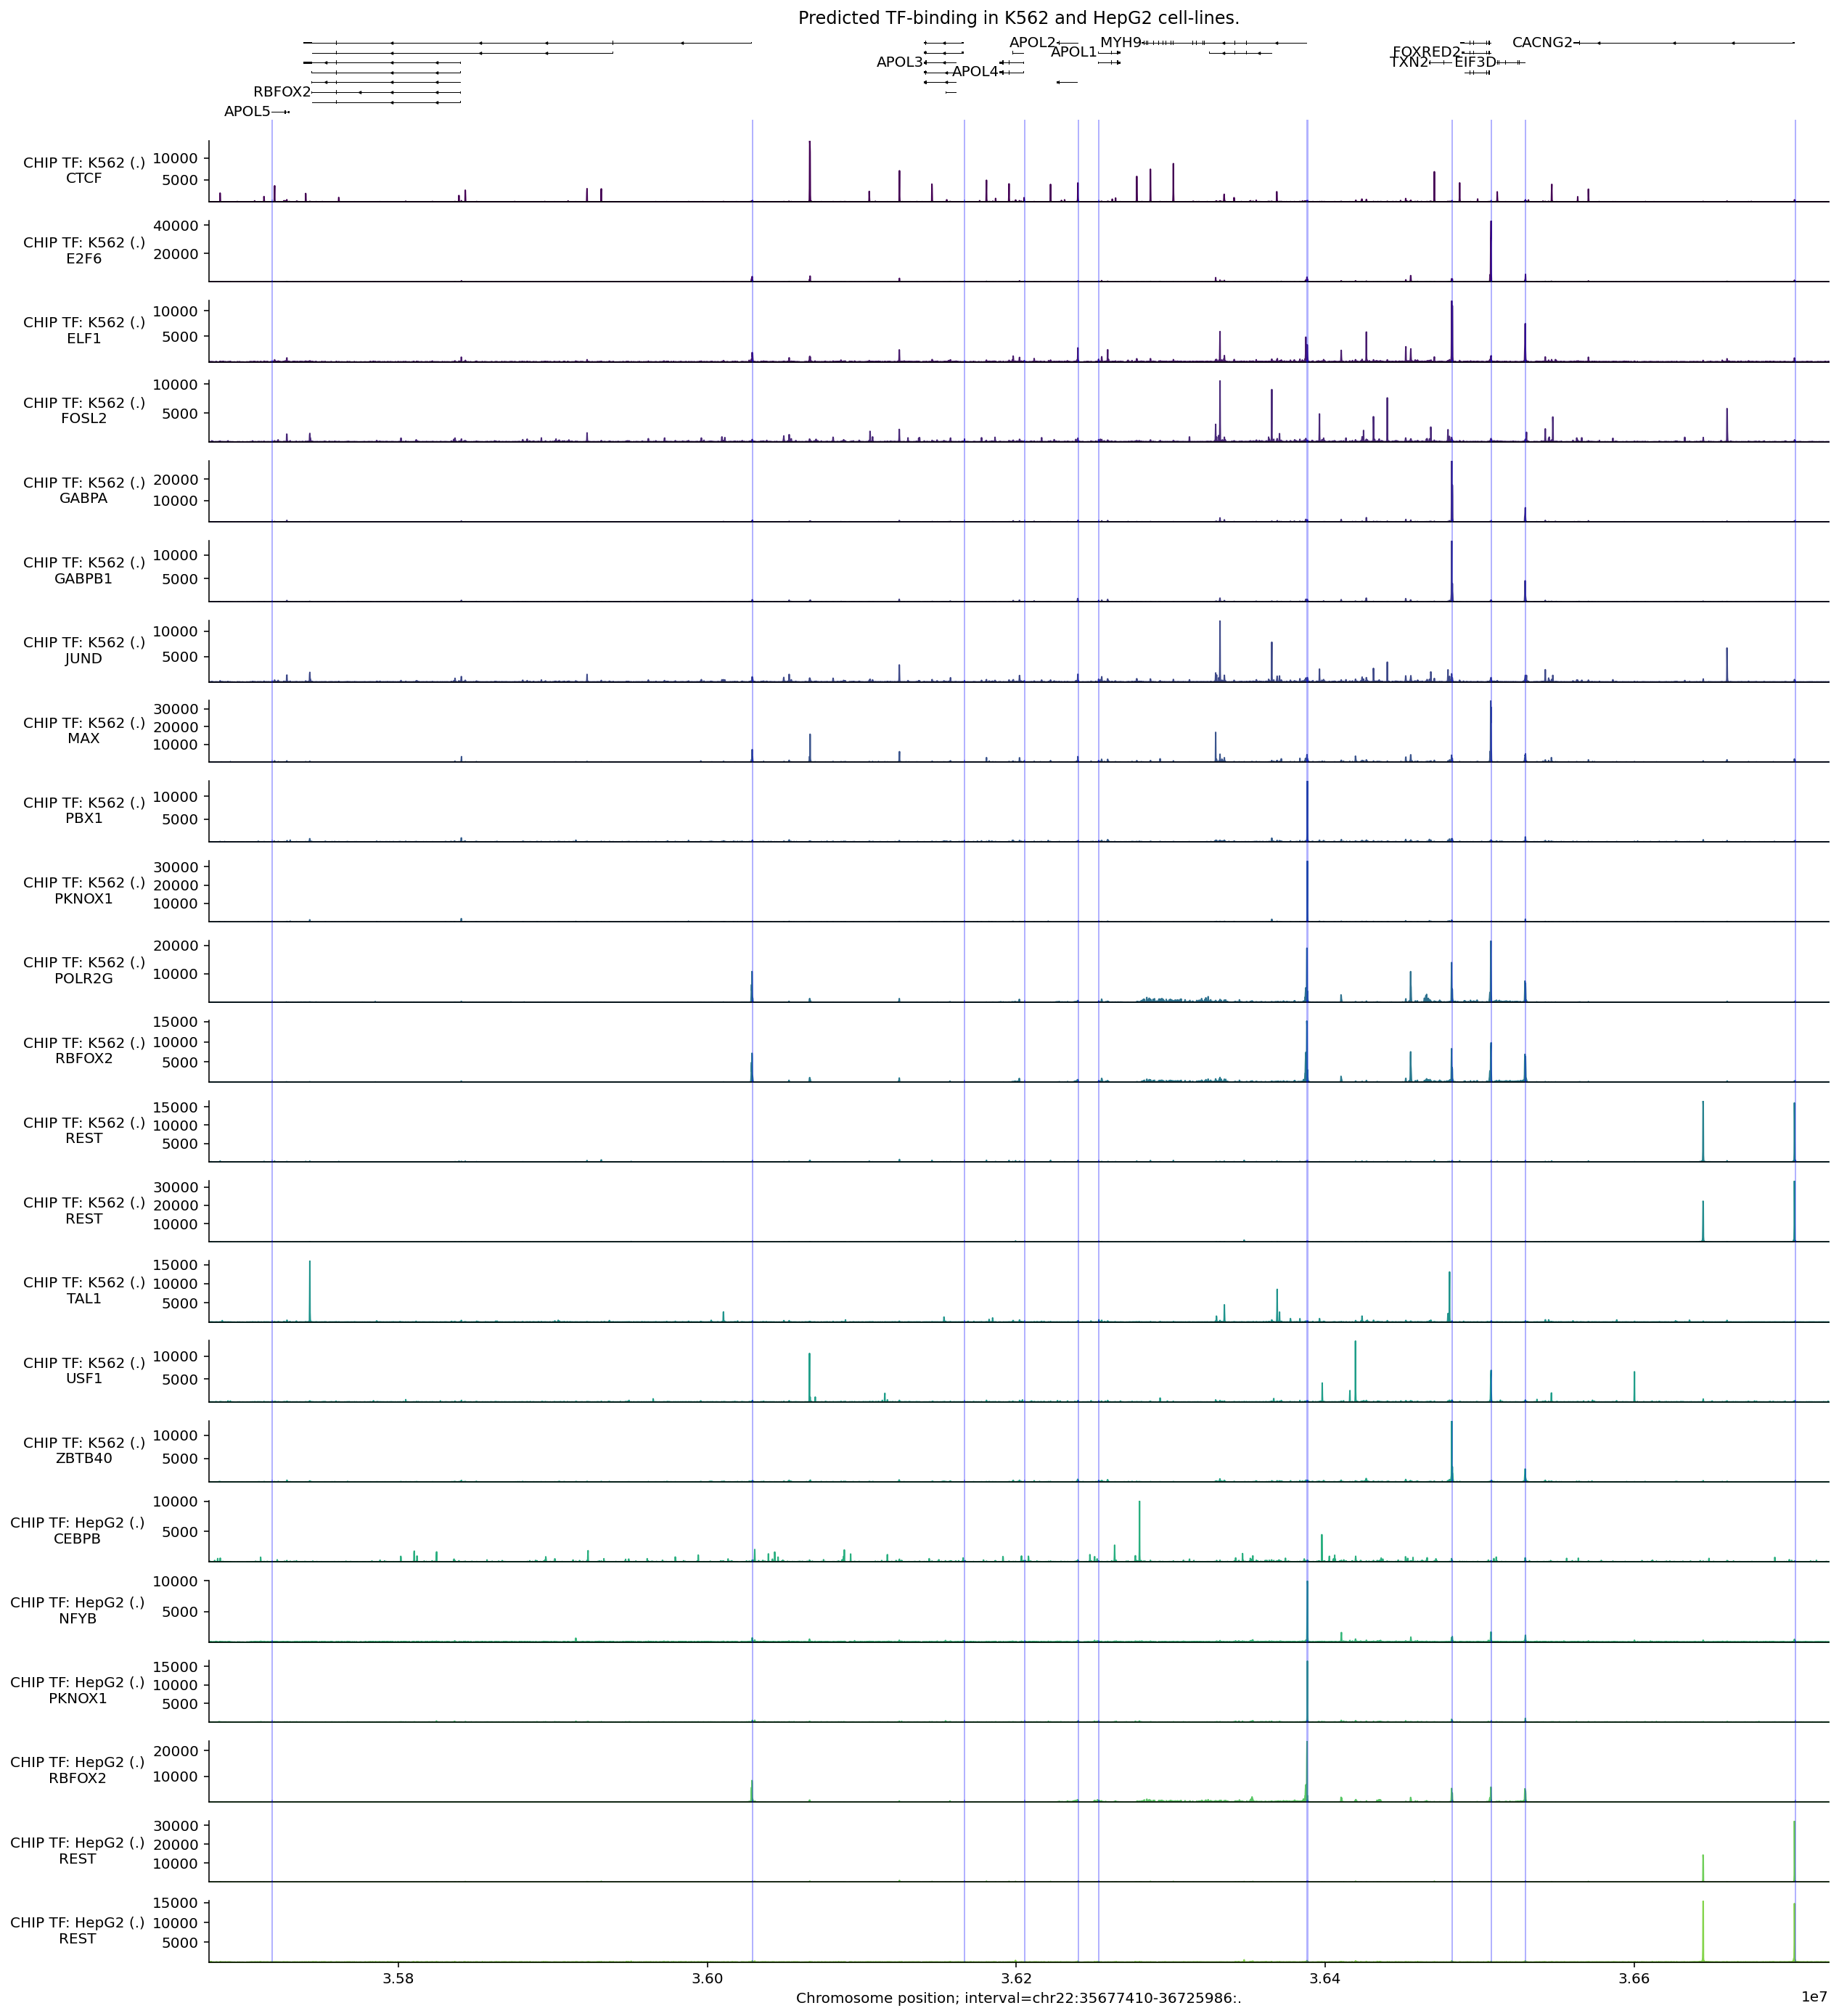

In [30]:
# Build plot.
plot_components.plot(
    components=[
        plot_components.TranscriptAnnotation(longest_transcripts),
        plot_components.Tracks(
            tdata=output_filtered,
            ylabel_template=(
                'CHIP TF: {biosample_name} ({strand})\n{transcription_factor}'
            ),
            filled=True,
        ),
    ],
    interval=interval,
    title='Predicted TF-binding in K562 and HepG2 cell-lines.',
    despine_keep_bottom=True,
    annotations=[
        plot_components.IntervalAnnotation(
            tss_as_intervals, alpha=0.3, colors='blue'
        )
    ],
)
plt.show()

Binding locations for the same protein (e.g.,
RBFOX2) appear largely the same across these two cell types, with some
change in magnitude. Peaks in predicted POLR2G binding, a component of RNA
Polymerase II, typically occur near TSS sites.

We can use the same process to select tracks with high peaks anywhere within the
*APOL4* gene interval:

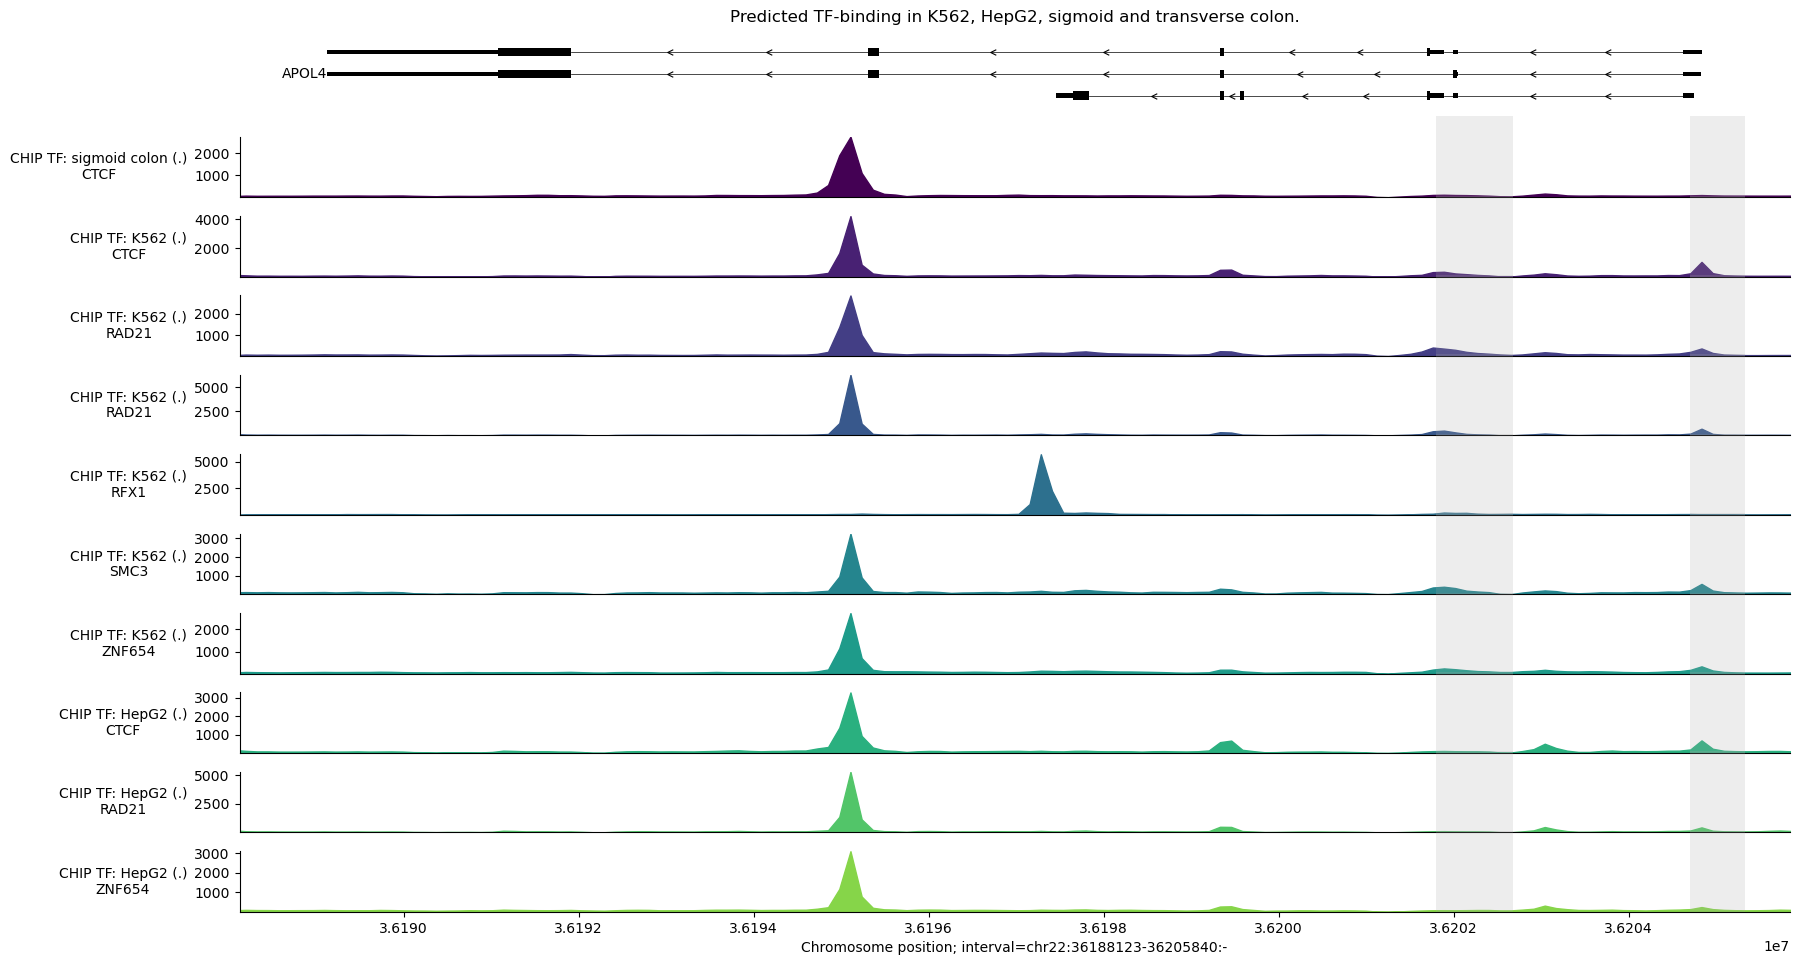

In [30]:
# Compute max predicted values per track in the APOL4 gene interval.
max_predictions = concatenated_chip_tf.slice_by_interval(
    apol4_interval, match_resolution=True
).values.max(axis=0)

# Filter to the 10 tracks with the highest predictions.
output_filtered = concatenated_chip_tf.filter_tracks(
    (max_predictions >= np.sort(max_predictions)[-10])
)

# Build plot.
plot_components.plot(
    [
        plot_components.TranscriptAnnotation(transcripts),
        plot_components.Tracks(
            tdata=output_filtered,
            ylabel_template=(
                'CHIP TF: {biosample_name} ({strand})\n{transcription_factor}'
            ),
            filled=True,
        ),
    ],
    interval=apol4_interval,
    annotations=[plot_components.IntervalAnnotation(promoter_intervals)],
    despine_keep_bottom=True,
    title='Predicted TF-binding in K562, HepG2, sigmoid and transverse colon.',
)
plt.show()

We observe a strong predicted CTCF peak near the second-to-last exon (counting
from the right), which is predicted across different tissues. 

We can average the signal for a transcription factor across tissues to simplify
the plot. For example, to plot the mean CTCF signal across tissues, we first
need to construct a new `TrackData` object:

In [32]:
mean_ctcf = output_filtered.values[
    :, output_filtered.metadata['transcription_factor'] == 'CTCF'
].mean(axis=1)

# Construct a new TrackData object from the mean values.
tdata_mean_ctcf = track_data.TrackData(
    values=mean_ctcf[:, None],
    metadata=pd.DataFrame(
        {'transcription_factor': ['CTCF'], 'name': ['mean'], 'strand': ['.']}
    ),
    interval=output_filtered.interval,
    resolution=output_filtered.resolution,
)

And then plot as usual:

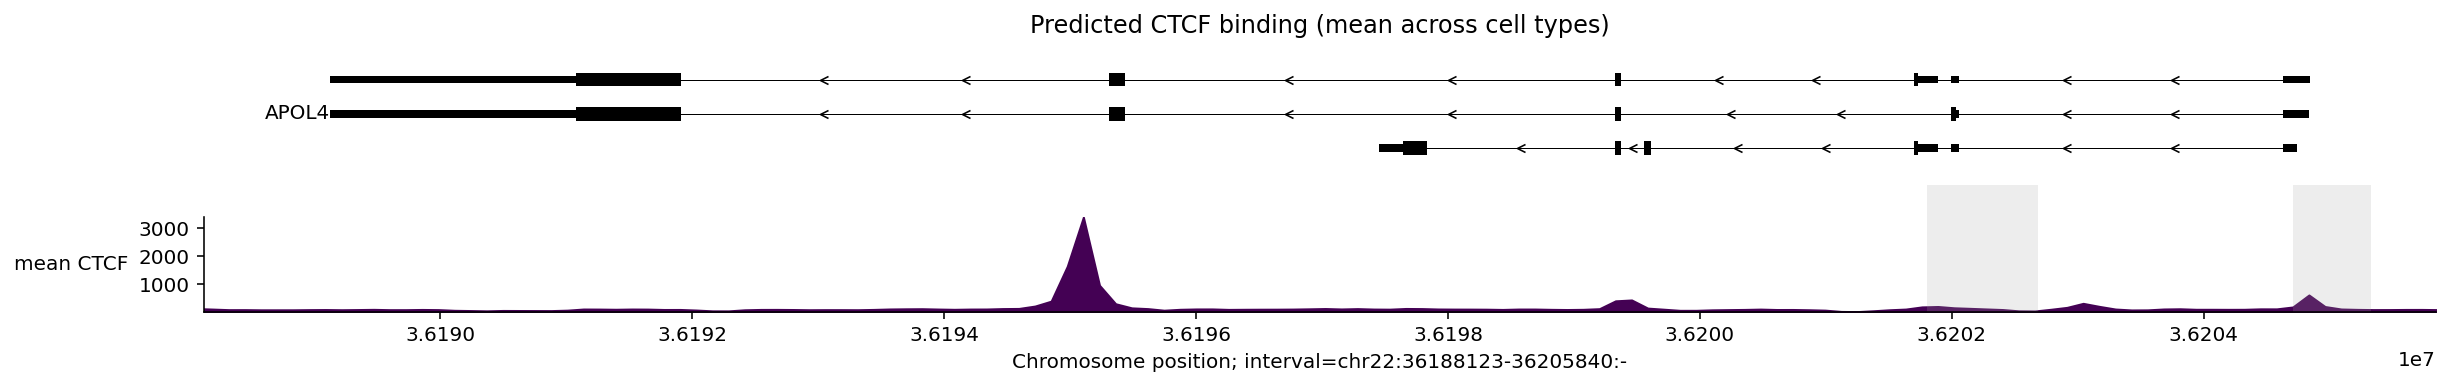

In [33]:
plot_components.plot(
    [
        plot_components.TranscriptAnnotation(transcripts),
        plot_components.Tracks(
            tdata=tdata_mean_ctcf,
            ylabel_template='{name} {transcription_factor}',
            filled=True,
        ),
    ],
    interval=apol4_interval,
    annotations=[plot_components.IntervalAnnotation(promoter_intervals)],
    despine_keep_bottom=True,
    title='Predicted CTCF binding (mean across cell types)',
)
plt.show()

## Contact maps

`CONTACT_MAPS` predicts 3D contact frequency between pairs of 2048 bp bins,
normalized for distance decay (observed over expected, from Hi-C and Micro-C
data). Use intervals substantially wider than 2048 bp.

Let's make contact map predictions for a colon carcinoma cell line:

In [34]:
condition = 'EFO:0002824'  # HCT116 colon carcinoma cell line.

output = dna_model.predict_interval(
    interval=interval,
    requested_outputs={dna_client.OutputType.CONTACT_MAPS},
    condition=condition,
)

And plot the predicted DNA-DNA contacts:

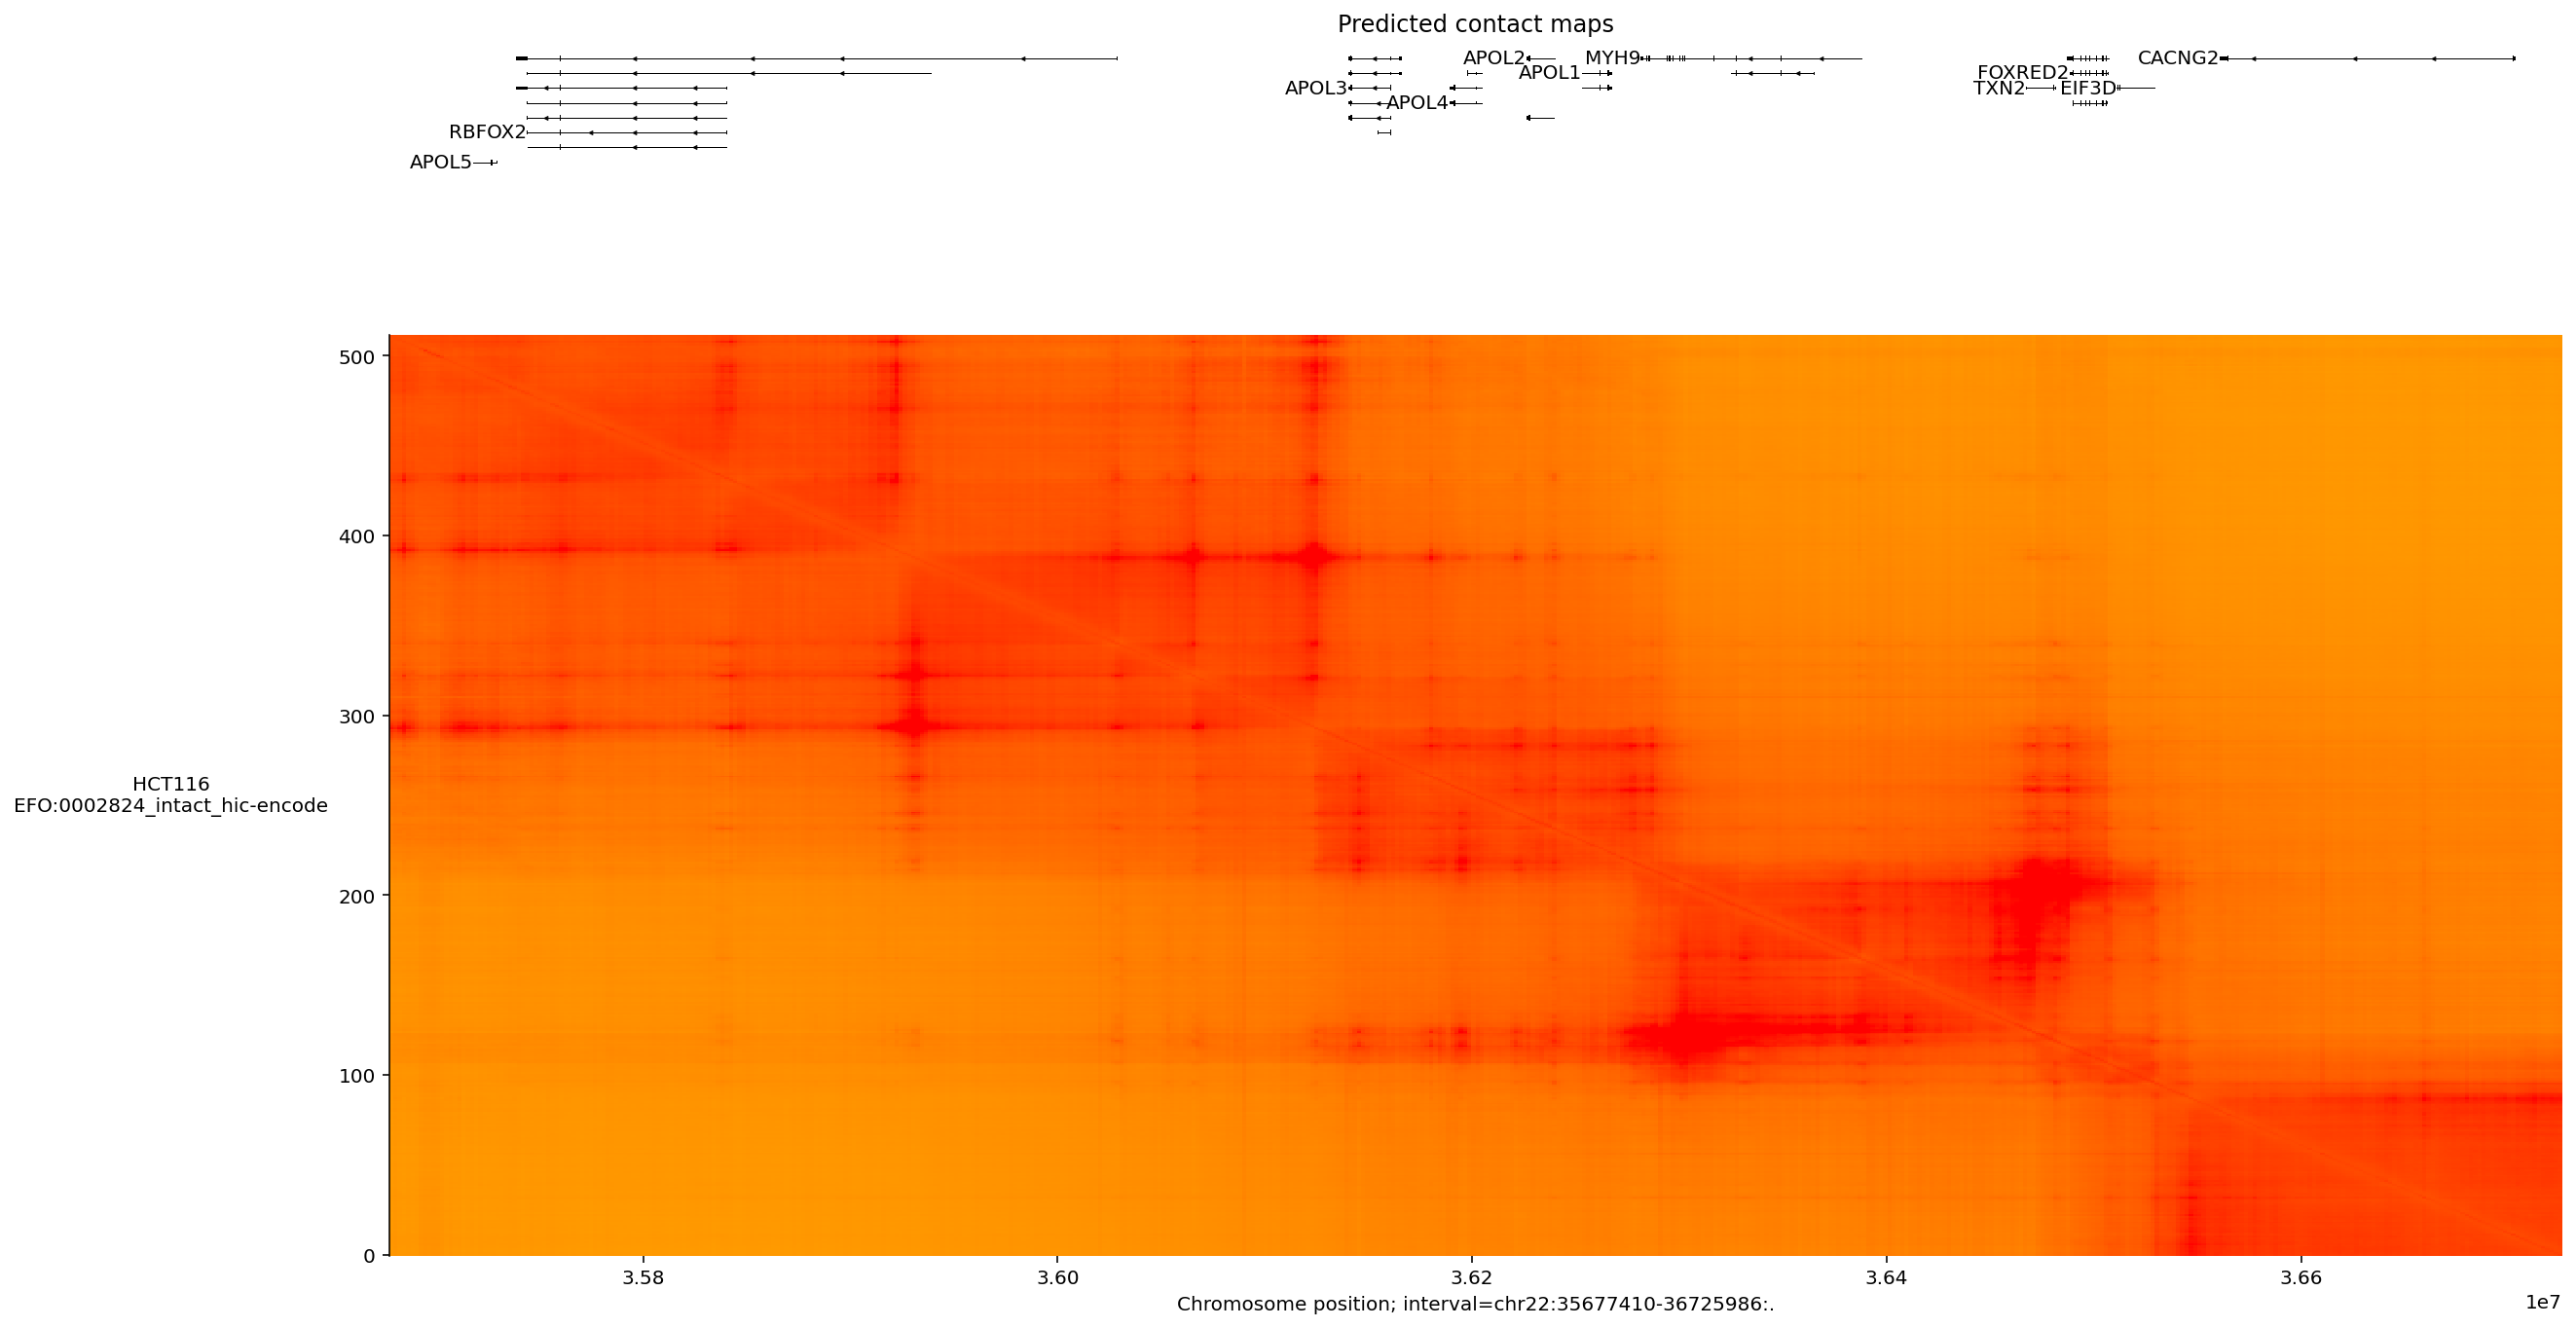

In [35]:
plot = plot_components.plot(
    [
        plot_components.TranscriptAnnotation(longest_transcripts),
        plot_components.ContactMaps(
            tdata=output.contact_maps,
            ylabel_template='{biosample_name}\n{name}',
            cmap='autumn_r',
            vmax=2.0,
        ),
    ],
    interval=interval,
    title='Predicted contact maps',
)
plt.show()

Several prominent interacting regions, potentially representing
topologically-associated domains (TADs), are visible as blocks.